In [1]:

# STEP 01: Install required libraries
!pip -q install openpyxl scikit-learn seaborn matplotlib pandas numpy


dataset upload

In [2]:

# STEP 02: Upload and load the dataset
from google.colab import files
import os
import pandas as pd
import numpy as np

uploaded = files.upload()

file_path = next(
    (name for name in uploaded
     if name.lower().endswith((".xlsx", ".xls", ".csv"))),
    None
)

if file_path is None:
    raise ValueError("Please upload an Excel or CSV dataset.")

if file_path.lower().endswith(".csv"):
    df = pd.read_csv(file_path, encoding="latin1")
else:
    df = pd.read_excel(file_path)

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
display(df.head())


Saving Online Retail.xlsx to Online Retail.xlsx
Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


data cleaning

In [3]:

# STEP 03: Clean transaction data
required_columns = [
    "InvoiceNo", "InvoiceDate",
    "Quantity", "UnitPrice", "CustomerID"
]

missing_columns = set(required_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

# Convert customer IDs to a consistent string format
df["CustomerID"] = (
    df["CustomerID"].astype("string").str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

before_rows = len(df)

df = df.dropna(subset=required_columns).copy()
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (~df["InvoiceNo"].str.startswith("C", na=False))
].copy()

df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Rows before cleaning:", before_rows)
print("Rows after cleaning:", len(df))
print("Rows removed:", before_rows - len(df))
print("Unique customers:", df["CustomerID"].nunique())
print("Total revenue:", round(df["Revenue"].sum(), 2))

display(df.head())


Rows before cleaning: 541909
Rows after cleaning: 397884
Rows removed: 144025
Unique customers: 4338
Total revenue: 8911407.9


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Exploratory Data Analysis (EDA)

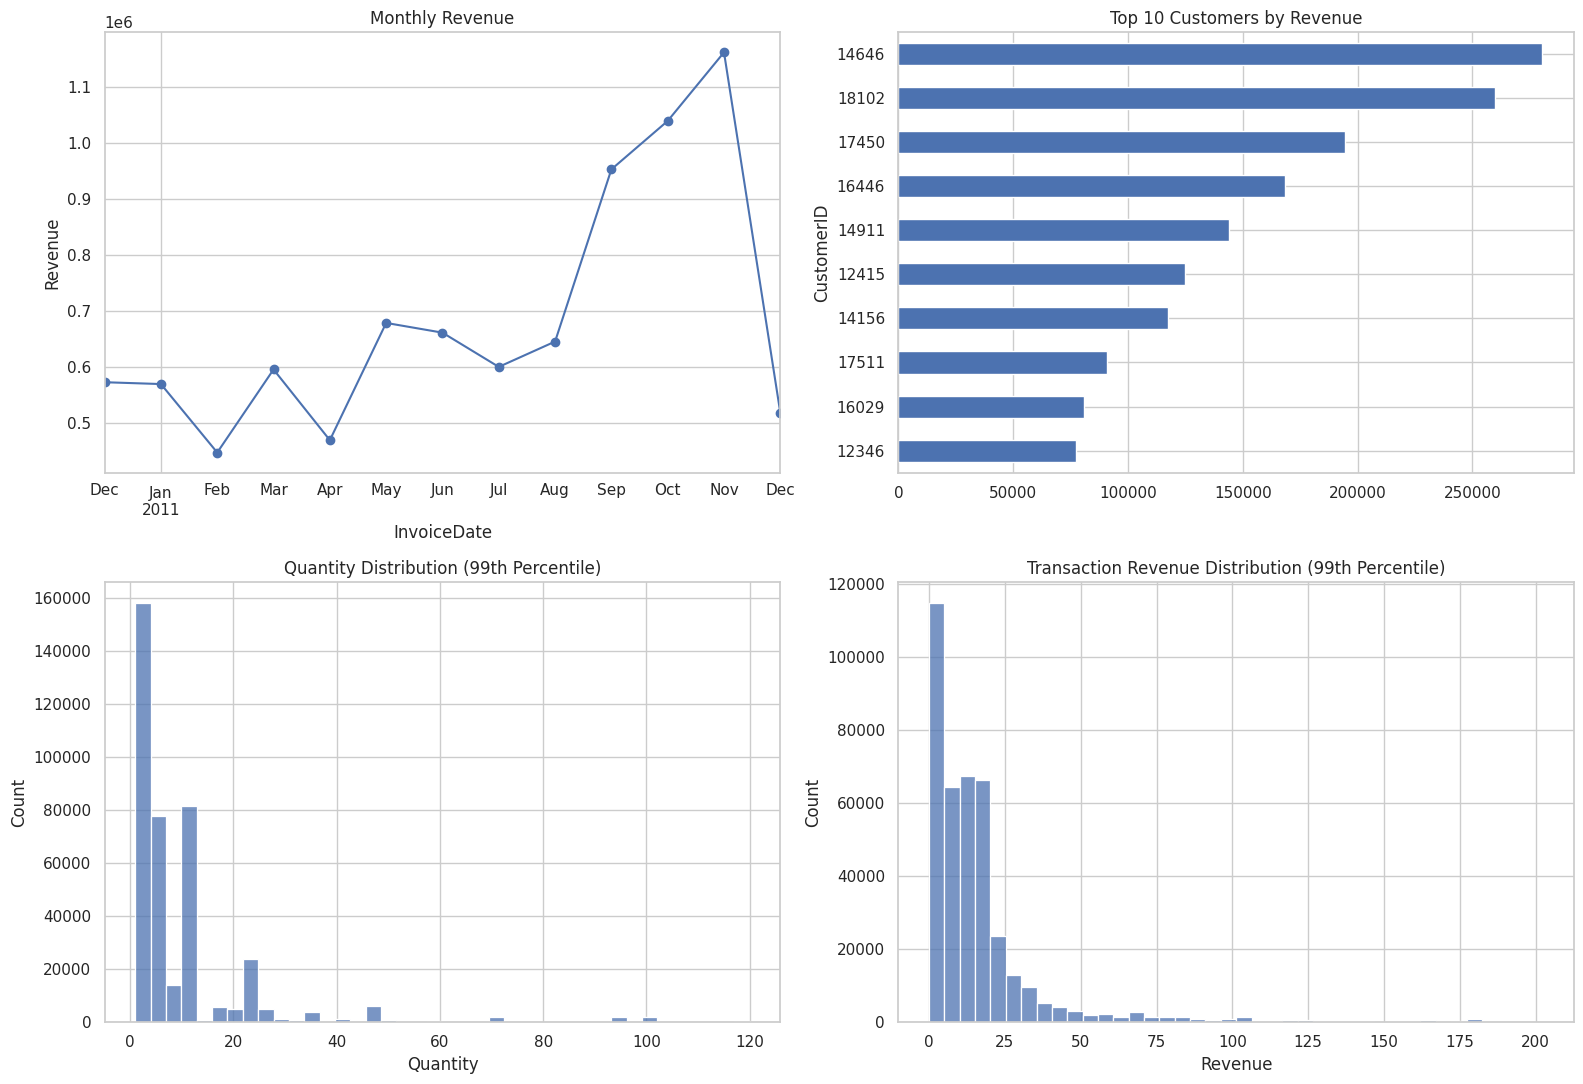

In [4]:

# STEP 04: Explore transaction patterns
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Monthly revenue trend
monthly_revenue = (
    df.set_index("InvoiceDate")["Revenue"]
      .resample("MS").sum()
)
monthly_revenue.plot(ax=axes[0, 0], marker="o")
axes[0, 0].set_title("Monthly Revenue")
axes[0, 0].set_ylabel("Revenue")

# Top 10 customers by total revenue
top_customers = (
    df.groupby("CustomerID")["Revenue"]
      .sum().nlargest(10).sort_values()
)
top_customers.plot(kind="barh", ax=axes[0, 1])
axes[0, 1].set_title("Top 10 Customers by Revenue")

# Order quantity distribution, capped for readability
sns.histplot(
    df.loc[df["Quantity"] <= df["Quantity"].quantile(0.99), "Quantity"],
    bins=40, ax=axes[1, 0]
)
axes[1, 0].set_title("Quantity Distribution (99th Percentile)")

# Transaction value distribution
sns.histplot(
    df.loc[df["Revenue"] <= df["Revenue"].quantile(0.99), "Revenue"],
    bins=40, ax=axes[1, 1]
)
axes[1, 1].set_title("Transaction Revenue Distribution (99th Percentile)")

plt.tight_layout()
plt.show()


RFM feature engineering
RFM এই project-এর মূল ভিত্তি।
- Recency: customer-এর সর্বশেষ purchase কত দিন আগে হয়েছে।
- Frequency: customer কতটি distinct invoice করেছে।
- Monetary: customer-এর মোট purchase revenue।

In [5]:

# STEP 05: Build the RFM customer table
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = (
    df.groupby("CustomerID")
      .agg(
          Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
          Frequency=("InvoiceNo", "nunique"),
          Monetary=("Revenue", "sum")
      )
      .reset_index()
)

rfm = rfm[
    (rfm["Recency"] >= 0) &
    (rfm["Frequency"] > 0) &
    (rfm["Monetary"] > 0)
].copy()

print("Number of customers:", len(rfm))
display(rfm.describe().round(2))
display(rfm.head())


Number of customers: 4338


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


RFM visualization

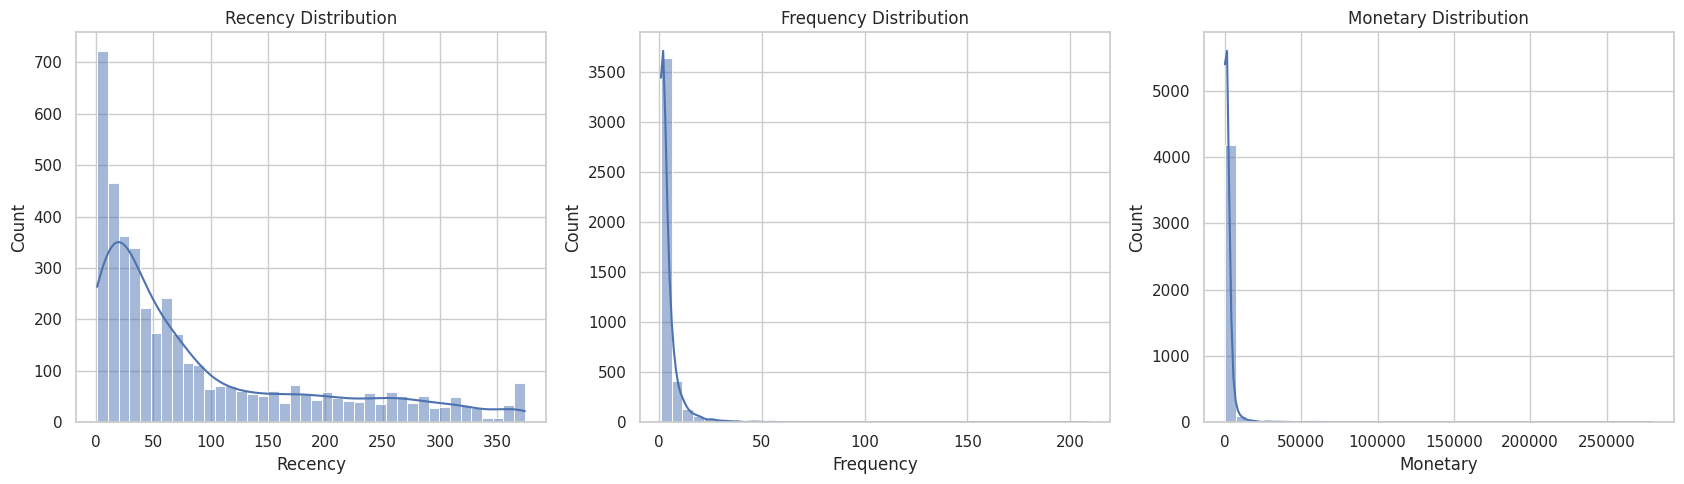

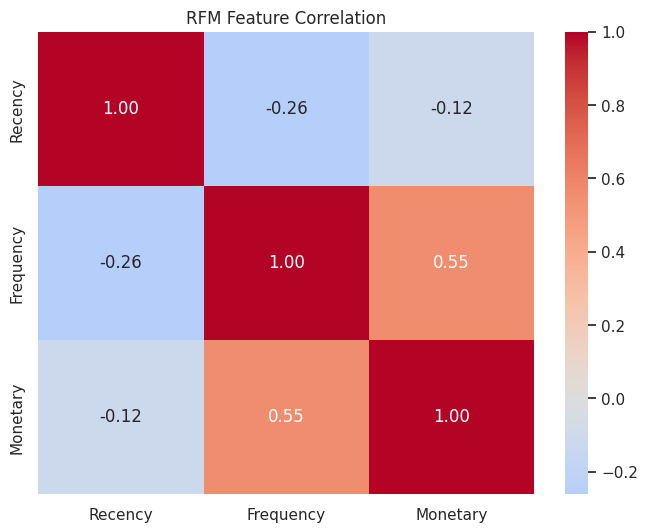

In [6]:

# STEP 06: Visualize customer-level RFM features
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=40, kde=True, ax=ax)
    ax.set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()

# Check relationships between RFM features
plt.figure(figsize=(8, 6))
sns.heatmap(
    rfm[["Recency", "Frequency", "Monetary"]].corr(),
    annot=True, cmap="coolwarm", center=0, fmt=".2f"
)
plt.title("RFM Feature Correlation")
plt.show()


Transform ও scale features

In [7]:

# STEP 07: Transform and scale RFM features
from sklearn.preprocessing import RobustScaler

features = ["Recency", "Frequency", "Monetary"]

X_log = np.log1p(rfm[features].clip(lower=0))

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_log)

print("Scaled feature matrix:", X_scaled.shape)
print("All values finite:", np.isfinite(X_scaled).all())


Scaled feature matrix: (4338, 3)
All values finite: True


K-Means-

,K,Inertia,Silhouette
0,2,2996.7033,0.4299
1,3,2257.4519,0.3309
2,4,1833.8376,0.3336
3,5,1534.0564,0.3128
4,6,1329.2192,0.3104
5,7,1187.8933,0.3063
6,8,1086.4302,0.2802


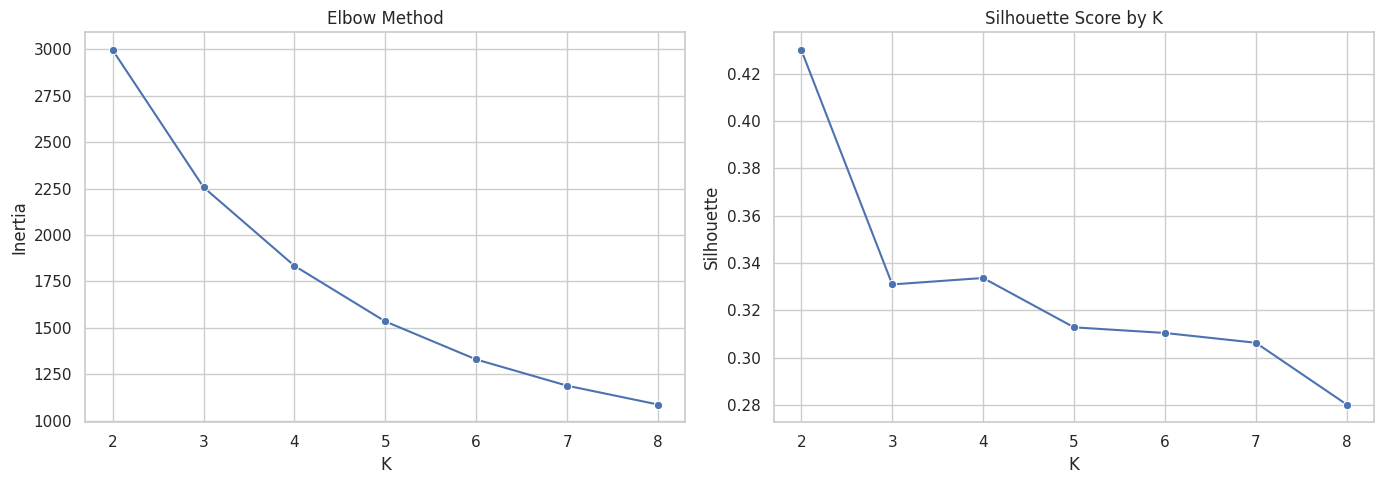

Initial candidate K: 2


In [8]:

# STEP 08: Find a suitable number of clusters
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    labels = model.fit_predict(X_scaled)

    k_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(
            X_scaled,
            labels,
            sample_size=min(10000, len(X_scaled)),
            random_state=42
        )
    })

k_results = pd.DataFrame(k_results)
display(k_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=k_results, x="K", y="Inertia", marker="o", ax=axes[0])
axes[0].set_title("Elbow Method")

sns.lineplot(data=k_results, x="K", y="Silhouette", marker="o", ax=axes[1])
axes[1].set_title("Silhouette Score by K")

plt.tight_layout()
plt.show()

best_k = int(k_results.loc[k_results["Silhouette"].idxmax(), "K"])
print("Initial candidate K:", best_k)


Train  compare 7 models

In [9]:

# STEP 09: Train seven clustering models
import time
import warnings

from sklearn.cluster import (
    KMeans, AgglomerativeClustering, DBSCAN,
    Birch, SpectralClustering, MiniBatchKMeans
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings("ignore")

n = len(X_scaled)
K = best_k

model_labels = {}
comparison_rows = []

# Use the same random sample for fairer metric evaluation
rng = np.random.RandomState(42)
eval_idx = rng.choice(n, size=min(n, 10000), replace=False)

# Six standard models
models = {
    "KMeans": KMeans(n_clusters=K, n_init=10, random_state=42),
    "Agglomerative": AgglomerativeClustering(n_clusters=K),
    "GaussianMixture": GaussianMixture(
        n_components=K, n_init=2, random_state=42
    ),
    "BIRCH": Birch(n_clusters=K, threshold=0.5),
    "MiniBatchKMeans": MiniBatchKMeans(
        n_clusters=K, n_init=5, random_state=42, batch_size=512
    )
}

# Spectral clustering uses a sample to control memory and runtime
spectral_n = min(n, 3000)
spectral_idx = rng.choice(n, size=spectral_n, replace=False)

models["Spectral"] = SpectralClustering(
    n_clusters=K,
    affinity="nearest_neighbors",
    n_neighbors=10,
    assign_labels="kmeans",
    random_state=42
)

for name, model in models.items():
    start = time.time()

    if name == "Spectral":
        # Spectral clustering is fitted on a manageable subset only
        labels_sample = model.fit_predict(X_scaled[spectral_idx])
        labels = np.full(n, -2, dtype=int)
        labels[spectral_idx] = labels_sample
        metric_idx = spectral_idx
    elif name == "GaussianMixture":
        model.fit(X_scaled)
        labels = model.predict(X_scaled)
        metric_idx = eval_idx
    else:
        labels = model.fit_predict(X_scaled)
        metric_idx = eval_idx

    elapsed = time.time() - start
    model_labels[name] = labels

    # Evaluate only customers with assignments from this model
    valid_idx = metric_idx[labels[metric_idx] >= 0]
    y = labels[valid_idx]
    X_eval = X_scaled[valid_idx]

    if len(np.unique(y)) >= 2 and len(valid_idx) > len(np.unique(y)):
        sil = silhouette_score(X_eval, y)
        dbi = davies_bouldin_score(X_eval, y)
        ch = calinski_harabasz_score(X_eval, y)
    else:
        sil, dbi, ch = np.nan, np.nan, np.nan

    comparison_rows.append({
        "Model": name,
        "Clusters": len(np.unique(y)),
        "Silhouette": sil,
        "Davies_Bouldin": dbi,
        "Calinski_Harabasz": ch,
        "Noise_%": 0.0,
        "Fit_Time_sec": round(elapsed, 2),
        "Evaluated_Customers": len(valid_idx)
    })

# DBSCAN: density-based clustering, including noise detection
best_dbscan = None

for eps in [0.3, 0.5, 0.7, 1.0, 1.3]:
    candidate = DBSCAN(eps=eps, min_samples=10)
    labels = candidate.fit_predict(X_scaled)

    valid_mask = labels != -1
    y = labels[valid_mask]
    n_clusters = len(np.unique(y))

    if n_clusters >= 2 and valid_mask.sum() > n_clusters:
        sil = silhouette_score(
            X_scaled[valid_mask],
            y,
            sample_size=min(10000, valid_mask.sum()),
            random_state=42
        )

        if best_dbscan is None or sil > best_dbscan["silhouette"]:
            best_dbscan = {
                "model": candidate,
                "labels": labels,
                "eps": eps,
                "silhouette": sil
            }

if best_dbscan is not None:
    labels = best_dbscan["labels"]
    model_labels["DBSCAN"] = labels

    valid_mask = labels != -1
    y = labels[valid_mask]
    X_valid = X_scaled[valid_mask]

    comparison_rows.append({
        "Model": f"DBSCAN eps={best_dbscan['eps']}",
        "Clusters": len(np.unique(y)),
        "Silhouette": silhouette_score(
            X_valid, y,
            sample_size=min(10000, len(y)),
            random_state=42
        ),
        "Davies_Bouldin": davies_bouldin_score(X_valid, y),
        "Calinski_Harabasz": calinski_harabasz_score(X_valid, y),
        "Noise_%": round(100 * np.mean(labels == -1), 2),
        "Fit_Time_sec": np.nan,
        "Evaluated_Customers": int(valid_mask.sum())
    })
else:
    print("DBSCAN found no usable multi-cluster solution in the tested range.")

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values(
    "Silhouette", ascending=False, na_position="last"
).reset_index(drop=True)

display(comparison_df.round(4))


,Model,Clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,Noise_%,Fit_Time_sec,Evaluated_Customers
0,KMeans,2,0.4299,0.8936,4353.4773,0.00,0.02,4338
1,MiniBatchKMeans,2,0.4291,0.8951,4352.1516,0.00,0.01,4338
2,BIRCH,2,0.4214,0.8142,2716.2397,0.00,0.05,4338
3,Agglomerative,2,0.4101,0.9239,4017.7998,0.00,0.59,4338
4,DBSCAN eps=0.3,2,0.2930,1.0678,2386.4677,2.77,NaN,4218
5,Spectral,2,0.2831,1.0560,1593.2552,0.00,0.34,3000
6,GaussianMixture,2,0.2810,1.0812,2250.6447,0.00,0.20,4338


Model performance visualization

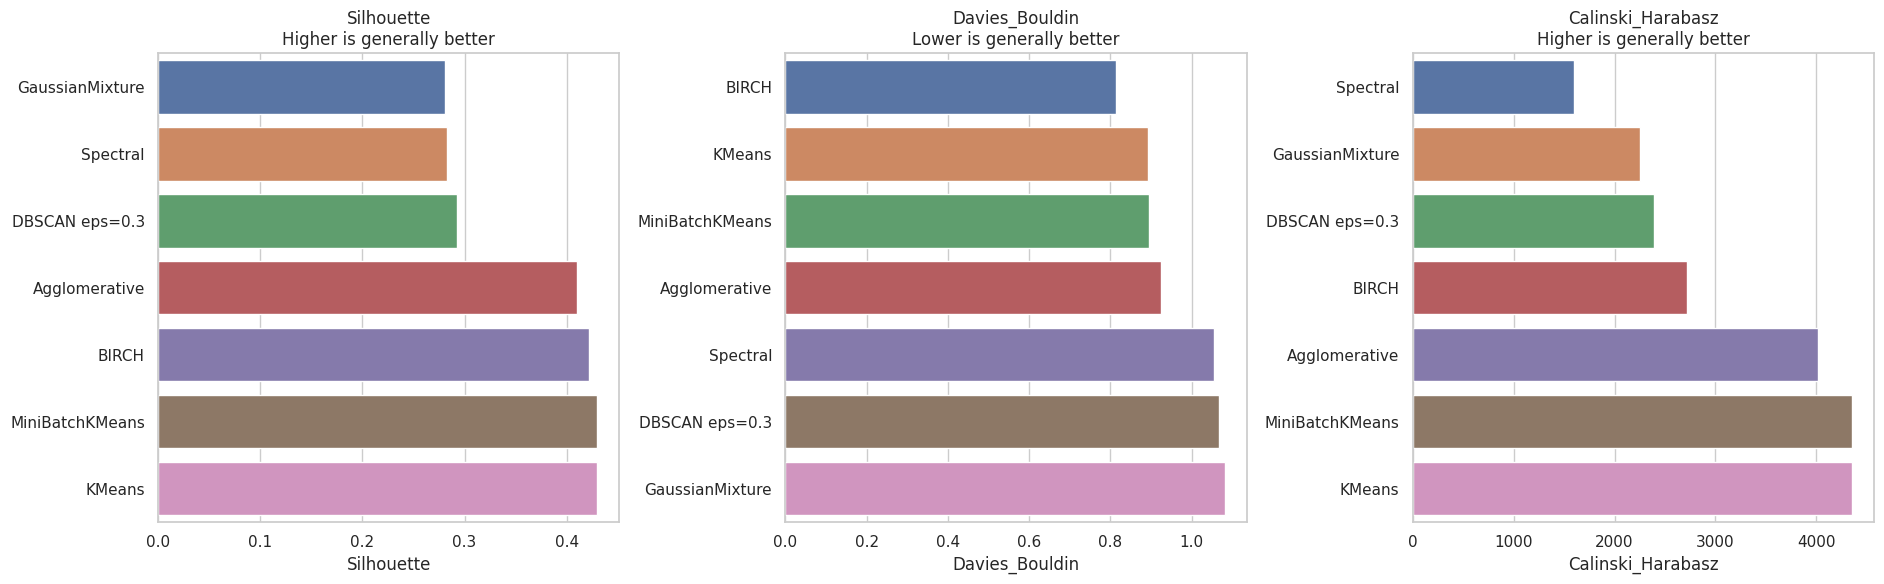

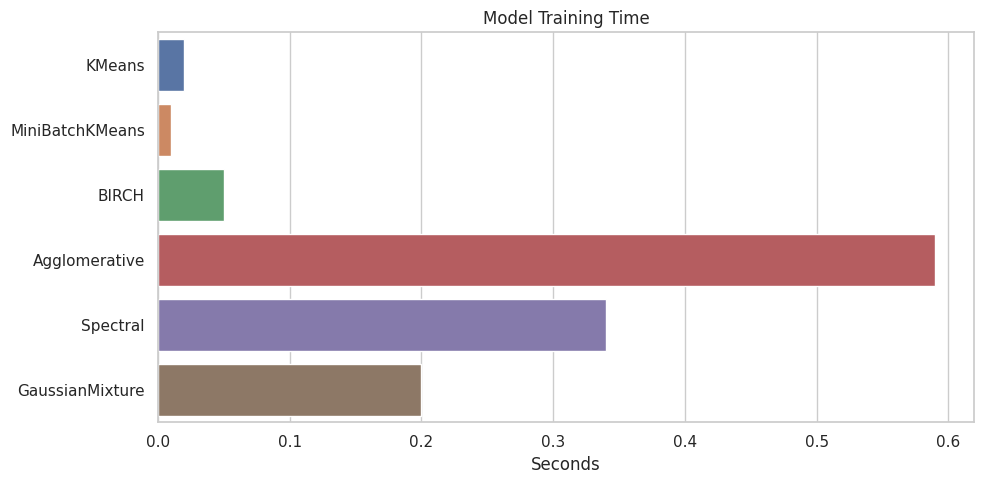

In [10]:

# STEP 10: Compare model evaluation metrics visually
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

metrics = [
    ("Silhouette", "Higher is generally better"),
    ("Davies_Bouldin", "Lower is generally better"),
    ("Calinski_Harabasz", "Higher is generally better")
]

for ax, (metric, subtitle) in zip(axes, metrics):
    plot_data = comparison_df.dropna(subset=[metric]).sort_values(metric)

    sns.barplot(
        data=plot_data,
        x=metric,
        y="Model",
        hue="Model",
        legend=False,
        ax=ax
    )
    ax.set_title(f"{metric}\n{subtitle}")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

# Compare model runtime
runtime_df = comparison_df.dropna(subset=["Fit_Time_sec"])

plt.figure(figsize=(10, 5))
sns.barplot(
    data=runtime_df,
    x="Fit_Time_sec",
    y="Model",
    hue="Model",
    legend=False
)
plt.title("Model Training Time")
plt.xlabel("Seconds")
plt.ylabel("")
plt.tight_layout()
plt.show()


PCA visualization

Variance explained: 94.09 %


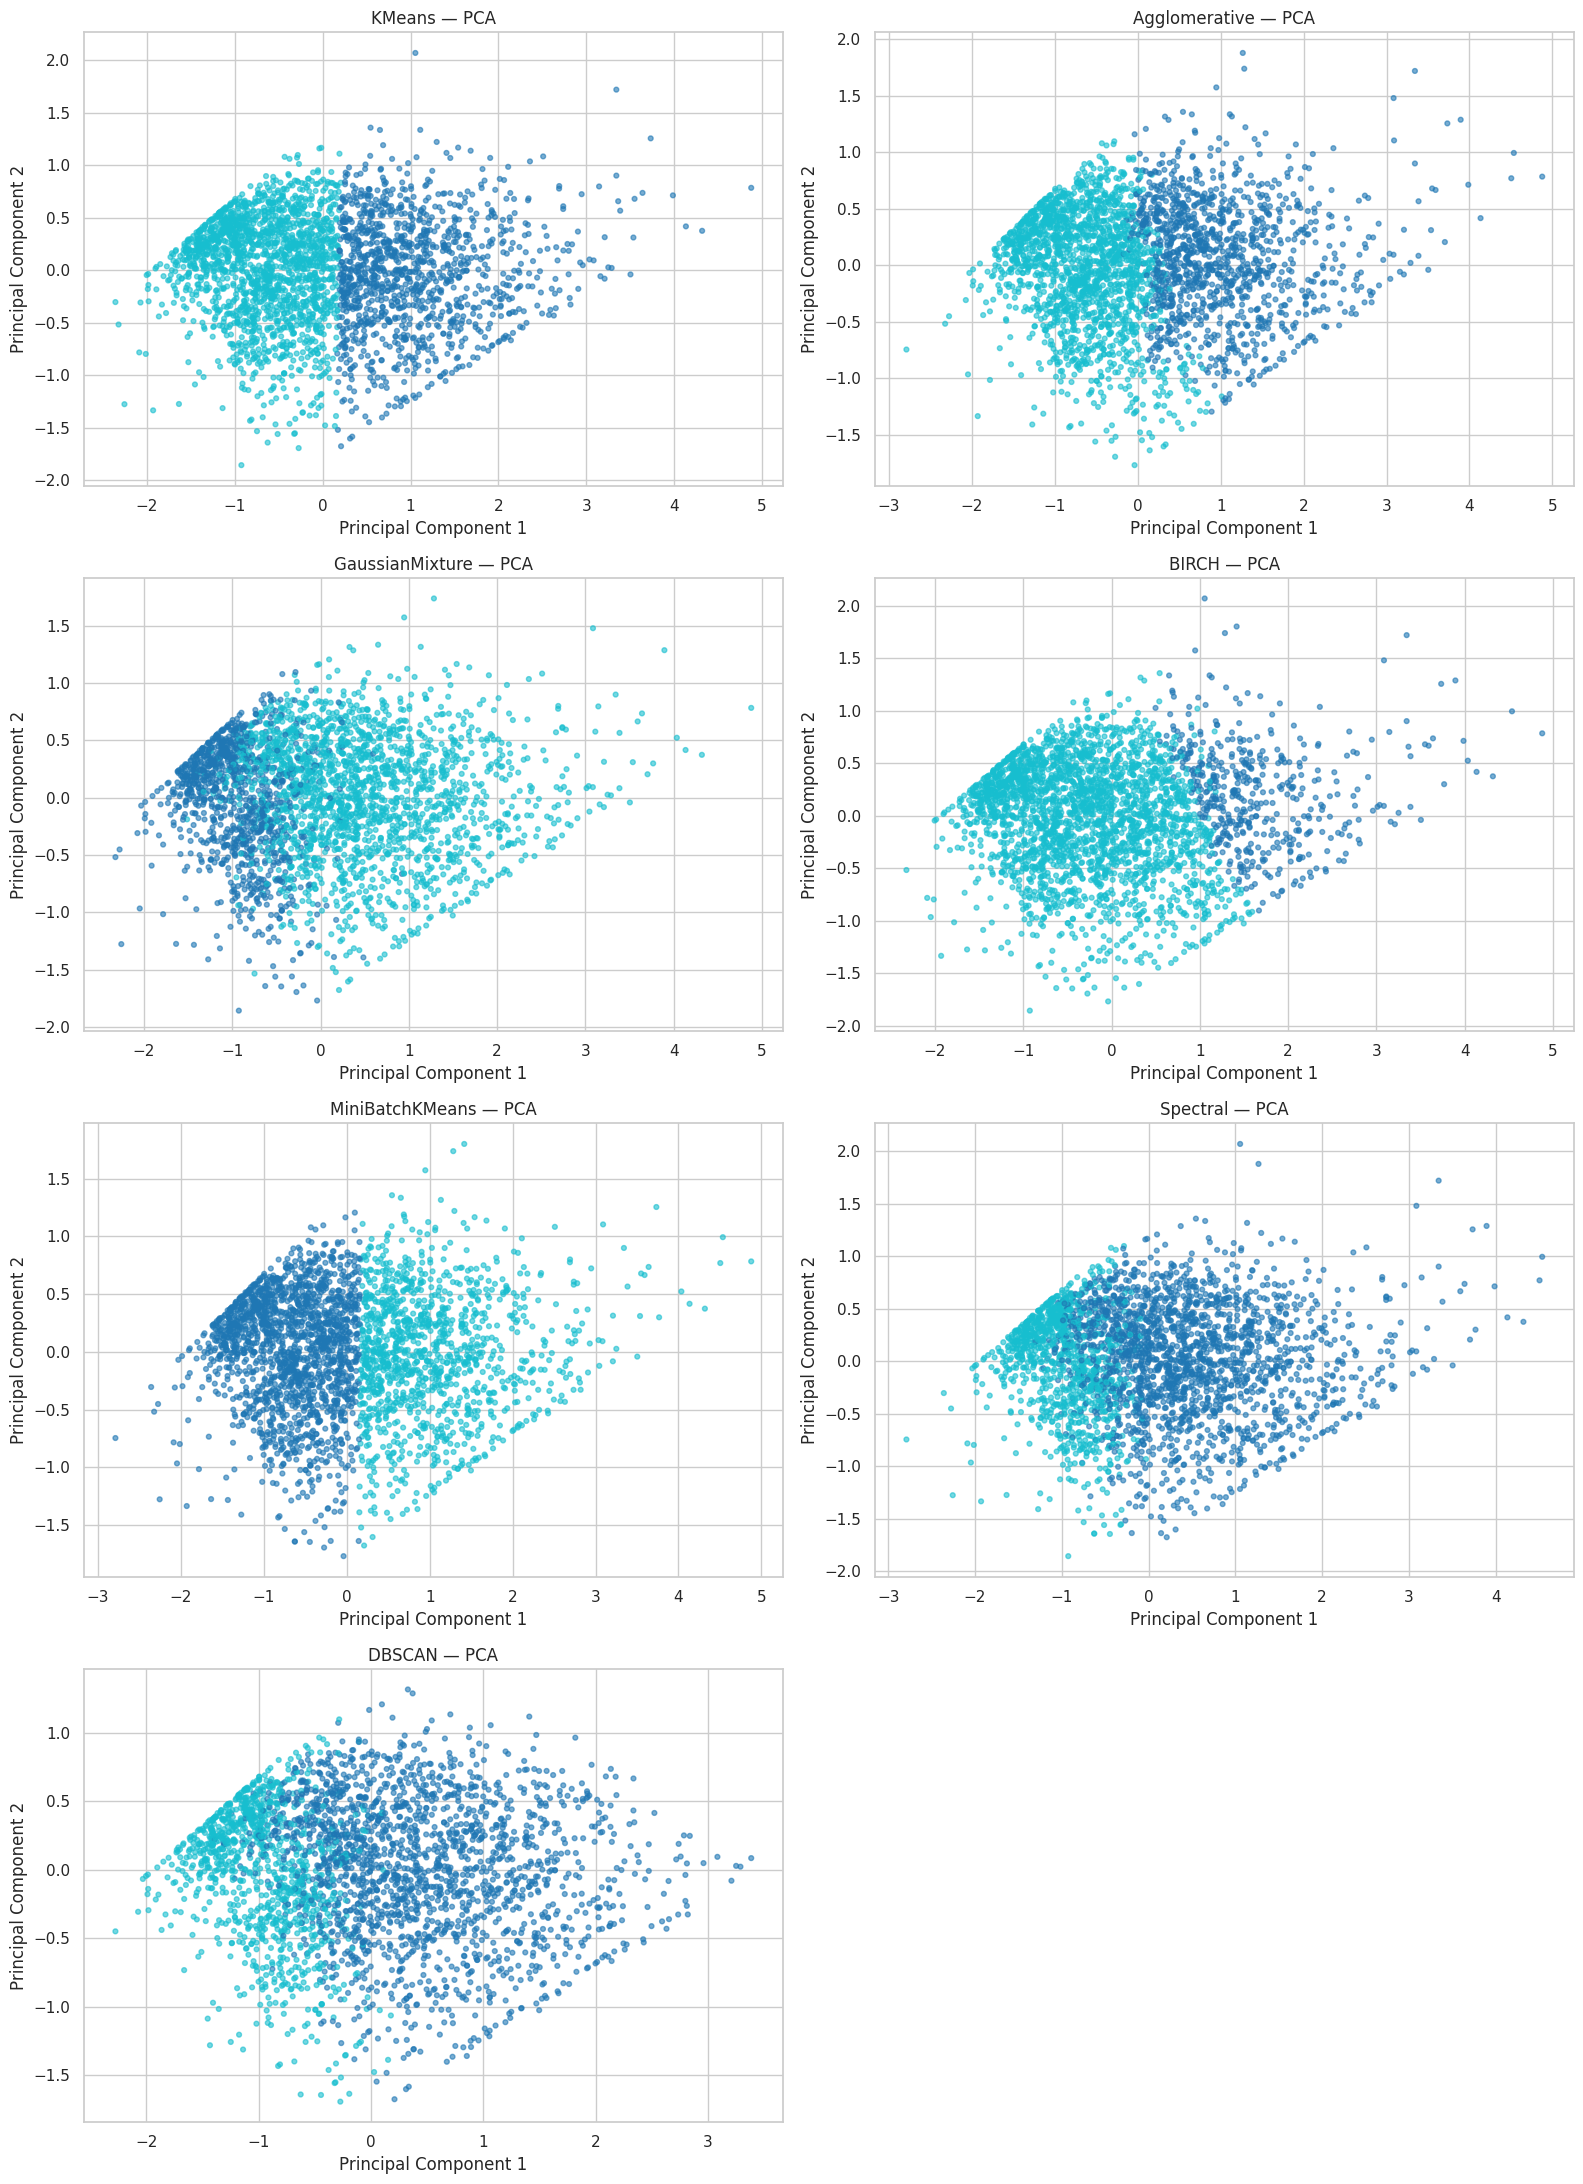

In [11]:

# STEP 11: Visualize cluster assignments using PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2), "%"
)

fig, axes = plt.subplots(4, 2, figsize=(16, 22))
axes = axes.flatten()

for ax, (name, labels) in zip(axes, model_labels.items()):
    # Exclude unassigned customers and sample for readable plots
    valid_idx = np.where(labels >= 0)[0]
    plot_idx = rng.choice(
        valid_idx,
        size=min(3000, len(valid_idx)),
        replace=False
    )

    ax.scatter(
        X_pca[plot_idx, 0],
        X_pca[plot_idx, 1],
        c=labels[plot_idx],
        cmap="tab10",
        s=12,
        alpha=0.6
    )

    ax.set_title(f"{name} — PCA")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

for ax in axes[len(model_labels):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


Cluster size comparison

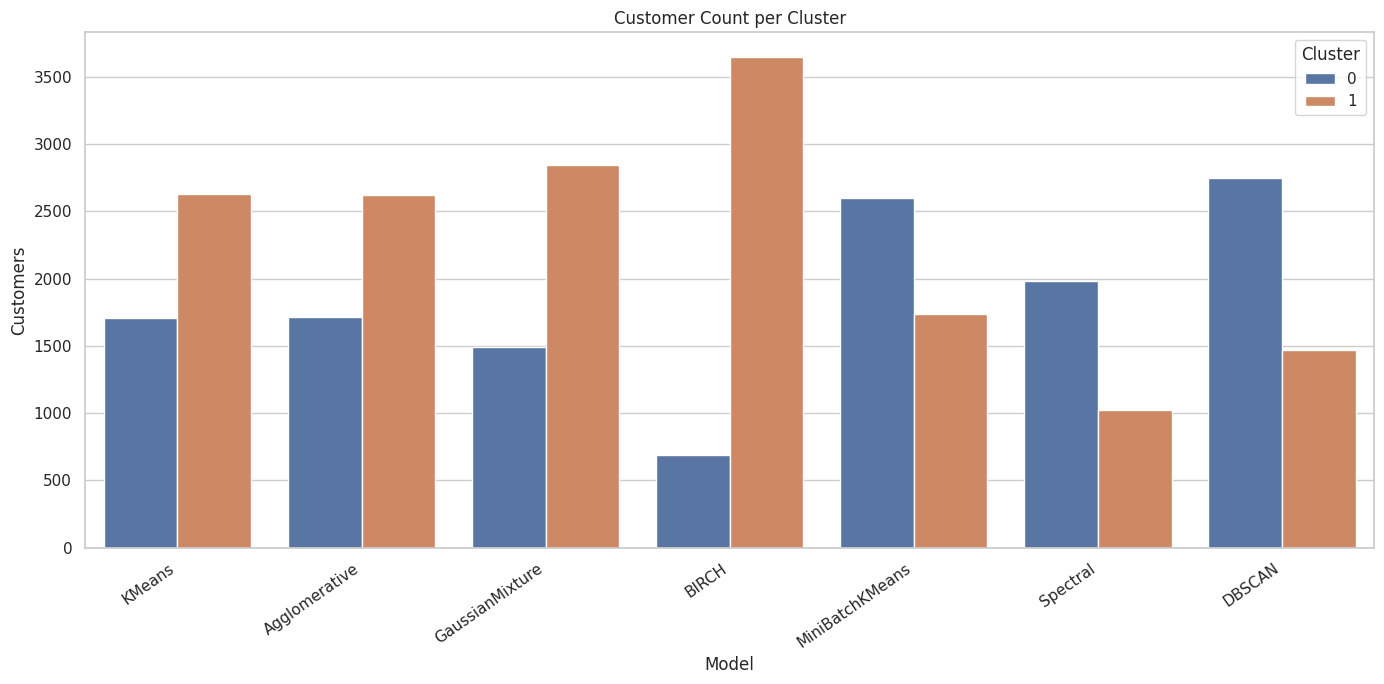

,Model,Cluster,Customers
0,KMeans,0,1710
1,KMeans,1,2628
2,Agglomerative,0,1716
3,Agglomerative,1,2622
4,GaussianMixture,0,1493
5,GaussianMixture,1,2845
6,BIRCH,0,688
7,BIRCH,1,3650
8,MiniBatchKMeans,0,2601
9,MiniBatchKMeans,1,1737


In [12]:

# STEP 12: Compare customer counts per cluster
size_rows = []

for name, labels in model_labels.items():
    valid_labels = labels[labels >= 0]

    counts = pd.Series(valid_labels).value_counts().sort_index()

    for cluster, count in counts.items():
        size_rows.append({
            "Model": name,
            "Cluster": str(cluster),
            "Customers": int(count)
        })

cluster_sizes = pd.DataFrame(size_rows)

plt.figure(figsize=(14, 7))
sns.barplot(
    data=cluster_sizes,
    x="Model",
    y="Customers",
    hue="Cluster"
)
plt.title("Customer Count per Cluster")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

display(cluster_sizes)


K-Means RFM heatmap

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Share_%,Revenue_Share_%
Cluster,,,,,,,
0,1710,27.54,8.29,4490.13,7678124.74,39.42,86.16
1,2628,134.83,1.66,469.29,1233283.16,60.58,13.84


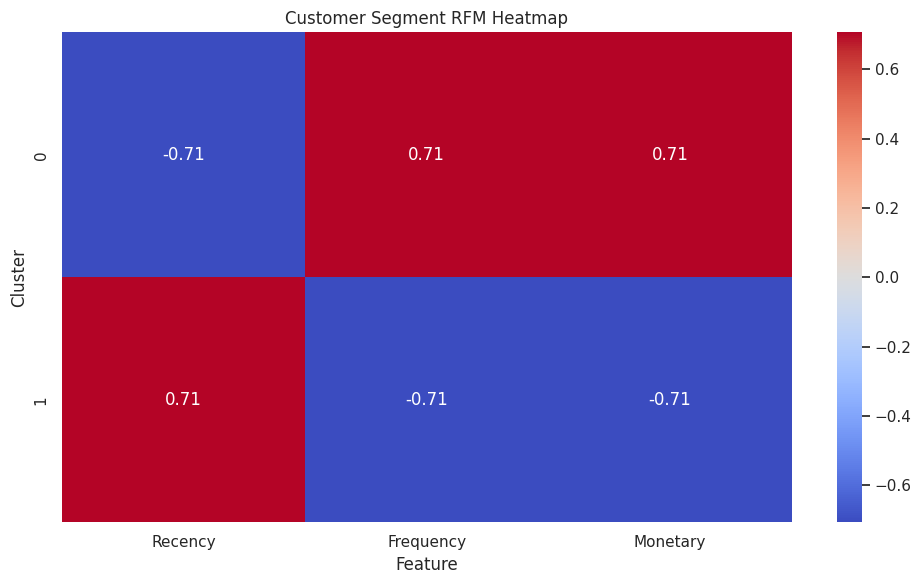

In [13]:

# STEP 13: Build and visualize K-Means customer profiles
rfm_profile_data = rfm[
    ["CustomerID", "Recency", "Frequency", "Monetary"]
].copy()

rfm_profile_data["Cluster"] = model_labels["KMeans"]

rfm_profile = rfm_profile_data.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
)

rfm_profile["Customer_Share_%"] = (
    rfm_profile["Customers"] / len(rfm_profile_data) * 100
)

rfm_profile["Revenue_Share_%"] = (
    rfm_profile["Total_Revenue"] /
    rfm_profile["Total_Revenue"].sum() * 100
)

display(rfm_profile.round(2))

# Standardize cluster means to compare relative feature patterns
heatmap_data = rfm_profile[
    ["Avg_Recency", "Avg_Frequency", "Avg_Monetary"]
].copy()

heatmap_data.columns = ["Recency", "Frequency", "Monetary"]

heatmap_scaled = (
    heatmap_data - heatmap_data.mean()
) / heatmap_data.std().replace(0, 1)

plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Customer Segment RFM Heatmap")
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


Business visualization

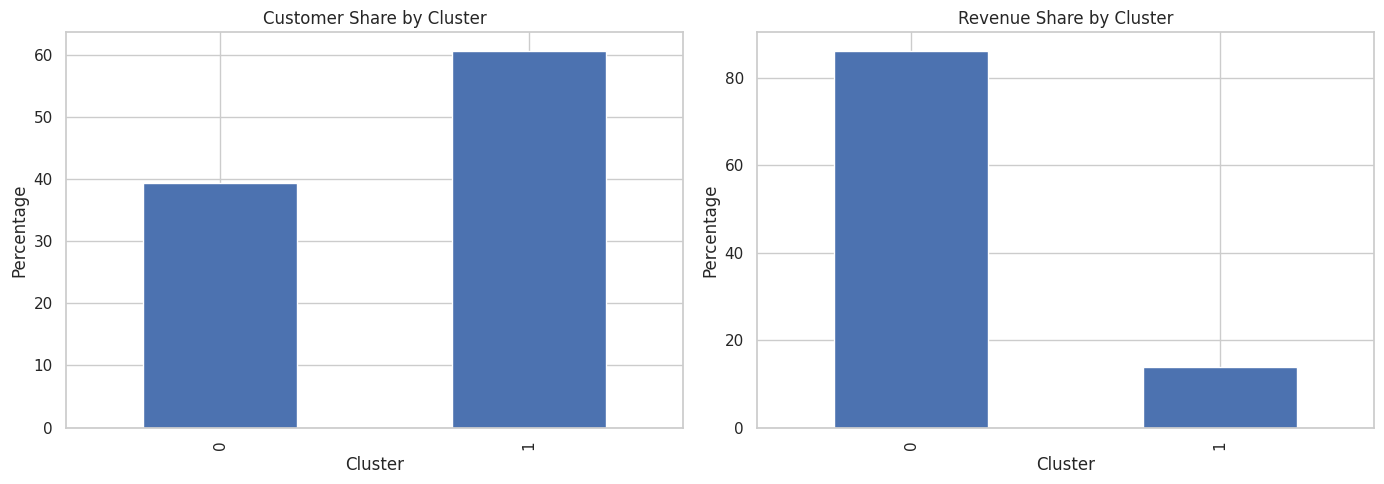

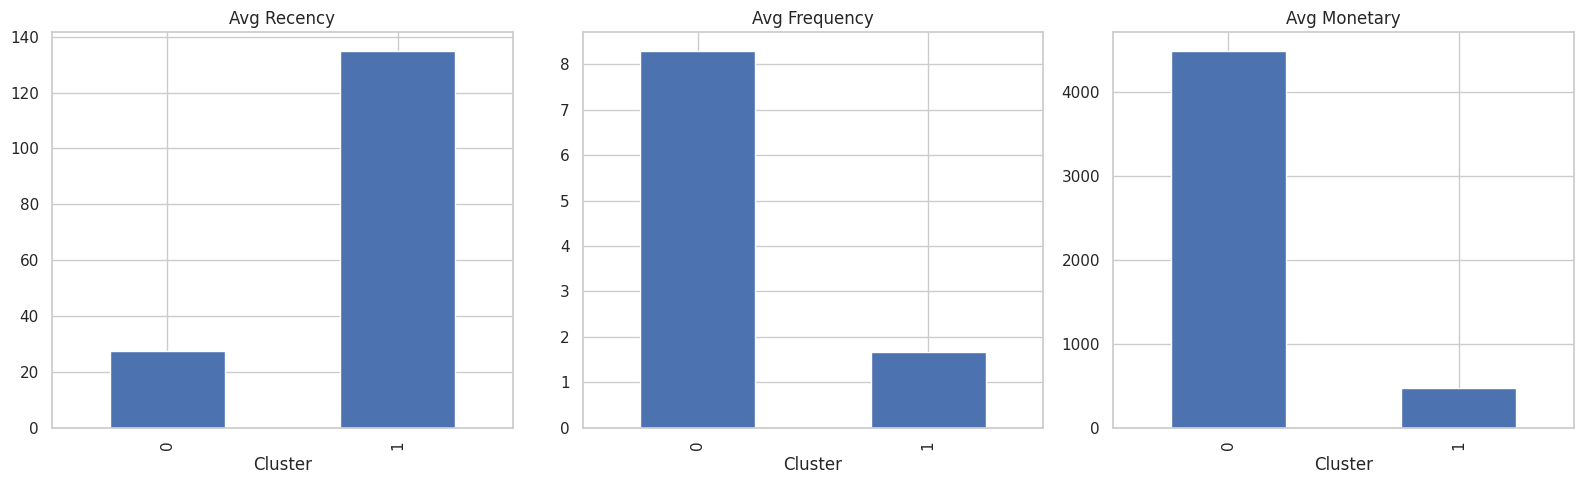

In [14]:

# STEP 14: Compare customer and revenue contributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rfm_profile["Customer_Share_%"].plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Customer Share by Cluster")
axes[0].set_ylabel("Percentage")
axes[0].set_xlabel("Cluster")

rfm_profile["Revenue_Share_%"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Revenue Share by Cluster")
axes[1].set_ylabel("Percentage")
axes[1].set_xlabel("Cluster")

plt.tight_layout()
plt.show()

# Compare average recency, frequency and monetary values
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(
    axes,
    ["Avg_Recency", "Avg_Frequency", "Avg_Monetary"]
):
    rfm_profile[col].plot(kind="bar", ax=ax)
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel("Cluster")

plt.tight_layout()
plt.show()


Generate business recommendations

In [15]:

# STEP 15: Generate preliminary marketing recommendations
median_recency = rfm["Recency"].median()
median_frequency = rfm["Frequency"].median()
median_monetary = rfm["Monetary"].median()

def recommend_segment(row):
    recent = row["Avg_Recency"] <= median_recency
    frequent = row["Avg_Frequency"] >= median_frequency
    valuable = row["Avg_Monetary"] >= median_monetary

    if recent and frequent and valuable:
        return "High-value customers: loyalty rewards and retention"

    if not recent and valuable:
        return "Potentially inactive valuable customers: re-engagement"

    if recent and not frequent:
        return "Recent or occasional customers: encourage repeat purchases"

    if frequent and not valuable:
        return "Frequent low-spend customers: relevant cross-sell offers"

    return "Test targeted offers and monitor customer response"

rfm_profile["Recommendation"] = rfm_profile.apply(
    recommend_segment, axis=1
)

display(rfm_profile.round(2))


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Share_%,Revenue_Share_%,Recommendation
Cluster,,,,,,,,
0,1710,27.54,8.29,4490.13,7678124.74,39.42,86.16,High-value customers: loyalty rewards and rete...
1,2628,134.83,1.66,469.29,1233283.16,60.58,13.84,Test targeted offers and monitor customer resp...


## STEP 16: Create Four Business Segments

This step creates four easy-to-explain business categories from the RFM table. It is separate from the K-Means clusters, because the selected K-Means model may produce only two clusters.

- **Champions / High Value:** repeat buyers, recent purchase, and spending at or above the Monetary median.
- **Loyal / Repeat Buyers:** repeat buyers with a recent purchase but below-median spending.
- **At Risk / Previously Frequent:** repeat buyers whose last purchase is older than the Recency median.
- **New or Occasional / Low Engagement:** customers with one distinct invoice.

Run this cell after STEP 15 and before the report-export step.

In [ ]:
# STEP 16: Create four business-friendly customer segments

# Median thresholds are calculated from the current cleaned dataset.
recency_median = float(rfm["Recency"].median())
frequency_median = float(rfm["Frequency"].median())
monetary_median = float(rfm["Monetary"].median())

segment_order = [
    "1 - Champions / High Value",
    "2 - Loyal / Repeat Buyers",
    "3 - At Risk / Previously Frequent",
    "4 - New or Occasional / Low Engagement"
]

def assign_business_segment(row):
    # One distinct invoice means the customer has purchased only once.
    # This rule takes priority even if that one invoice had a high value.
    if row["Frequency"] <= 1:
        return "4 - New or Occasional / Low Engagement"

    # Repeat buyers who have not purchased recently may need a win-back offer.
    if row["Recency"] > recency_median:
        return "3 - At Risk / Previously Frequent"

    # Among recent repeat buyers, separate higher-spend and lower-spend customers.
    if row["Monetary"] >= monetary_median:
        return "1 - Champions / High Value"

    return "2 - Loyal / Repeat Buyers"


# Add a business segment label for every customer in the RFM table.
rfm["Business_Segment_4"] = rfm.apply(assign_business_segment, axis=1)

# Summarize customer and revenue contribution for each of the four segments.
business_segment_profile = (
    rfm.groupby("Business_Segment_4")
       .agg(
           Customers=("CustomerID", "count"),
           Avg_Recency=("Recency", "mean"),
           Avg_Frequency=("Frequency", "mean"),
           Avg_Monetary=("Monetary", "mean"),
           Total_Revenue=("Monetary", "sum")
       )
       .reindex(segment_order)
       .reset_index()
)

business_segment_profile["Customer_Share_%"] = (
    business_segment_profile["Customers"] / len(rfm) * 100
)
business_segment_profile["Revenue_Share_%"] = (
    business_segment_profile["Total_Revenue"] /
    business_segment_profile["Total_Revenue"].sum() * 100
)

segment_recommendations = {
    "1 - Champions / High Value":
        "Reward loyalty; protect retention; test VIP benefits.",
    "2 - Loyal / Repeat Buyers":
        "Encourage larger baskets with relevant bundles and cross-sell.",
    "3 - At Risk / Previously Frequent":
        "Run win-back campaigns and measure reactivation.",
    "4 - New or Occasional / Low Engagement":
        "Use onboarding, second-purchase offers, and low-cost tests."
}
business_segment_profile["Suggested_Action"] = (
    business_segment_profile["Business_Segment_4"].map(segment_recommendations)
)

# Document the thresholds and the exact business rules used.
segment_rules = pd.DataFrame([
    {
        "Metric": "Recency median (days)",
        "Threshold": round(recency_median, 2),
        "Interpretation": "For repeat buyers, Recency above this value is At Risk."
    },
    {
        "Metric": "Frequency median (invoices)",
        "Threshold": round(frequency_median, 2),
        "Interpretation": "Context metric; Frequency = 1 is classified as a one-time buyer."
    },
    {
        "Metric": "Monetary median (revenue)",
        "Threshold": round(monetary_median, 2),
        "Interpretation": "For recent repeat buyers, at/above the median is Champions."
    },
    {
        "Metric": "Rule: Champions / High Value",
        "Threshold": "Frequency > 1, Recency <= median, Monetary >= median",
        "Interpretation": "Recent repeat buyer with higher spending."
    },
    {
        "Metric": "Rule: Loyal / Repeat Buyers",
        "Threshold": "Frequency > 1, Recency <= median, Monetary < median",
        "Interpretation": "Recent repeat buyer with lower spending."
    },
    {
        "Metric": "Rule: At Risk / Previously Frequent",
        "Threshold": "Frequency > 1, Recency > median",
        "Interpretation": "Repeat buyer whose last purchase was longer ago."
    },
    {
        "Metric": "Rule: New or Occasional / Low Engagement",
        "Threshold": "Frequency = 1",
        "Interpretation": "Customer has only one distinct invoice in this dataset."
    }
])

print("Customers in RFM table:", len(rfm))
print("Recency median:", round(recency_median, 2))
print("Frequency median:", round(frequency_median, 2))
print("Monetary median:", round(monetary_median, 2))
display(
    business_segment_profile[
        ["Business_Segment_4", "Customers", "Customer_Share_%",
         "Revenue_Share_%", "Suggested_Action"]
    ].round(2)
)
display(segment_rules)


## STEP 17: Export report ও results

Run this cell after STEP 16. It exports the model comparison, every customer assignment, both profile summaries, the segment rules, and the K-selection results to Excel.

In [ ]:
# STEP 17: Export the complete project results

# Include the new Business_Segment_4 label and all model cluster assignments.
assignments = rfm.copy()

for name, labels in model_labels.items():
    assignments[f"Cluster_{name}"] = labels

output_file = "customer_segmentation_complete_report.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    comparison_df.to_excel(
        writer, sheet_name="Model Comparison", index=False
    )
    assignments.to_excel(
        writer, sheet_name="Customer Assignments", index=False
    )
    rfm_profile.to_excel(
        writer, sheet_name="Business Profile"
    )
    k_results.to_excel(
        writer, sheet_name="K Selection", index=False
    )
    cluster_sizes.to_excel(
        writer, sheet_name="Cluster Sizes", index=False
    )
    business_segment_profile.to_excel(
        writer, sheet_name="Four Business Segments", index=False
    )
    segment_rules.to_excel(
        writer, sheet_name="Segment Rules", index=False
    )

print("Report saved:", output_file)
print("Report sheets:")
print(
    "Model Comparison, Customer Assignments, Business Profile, "
    "K Selection, Cluster Sizes, Four Business Segments, Segment Rules"
)

from google.colab import files
files.download(output_file)
